## 1. Loading and Inspecting RFM Data

The customer-level RFM dataset generated in the previous notebook is loaded for exploratory data analysis and preprocessing.

Each record represents an individual customer, described by three behavioural features: Recency, Frequency, and Monetary.

The CustomerID column is retained as an identifier but excluded from the clustering features.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42

In [3]:
rfm = pd.read_csv("../data/processed/customer_rfm.csv")

print("Dataset shape:", rfm.shape)
print("\nData types: ")
print(rfm.dtypes)

print("\nMissing values: ")
print(rfm.isnull().sum())

print("RFM Description")
rfm[["Recency", "Frequency", "Monetary"]].describe()

Dataset shape: (4338, 4)

Data types: 
CustomerID    float64
Recency         int64
Frequency       int64
Monetary      float64
dtype: object

Missing values: 
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64
RFM Description


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


## 2. Exploratory Data Analysis of RFM Features

Exploratory data analysis is performed to understand the distribution and characteristics of customer purchasing behaviour.

Histograms are used to examine the distribution, skewness, and presence of extreme values in Recency, Frequency, and Monetary features.

This analysis helps determine whether feature transformations are necessary before applying clustering algorithms.

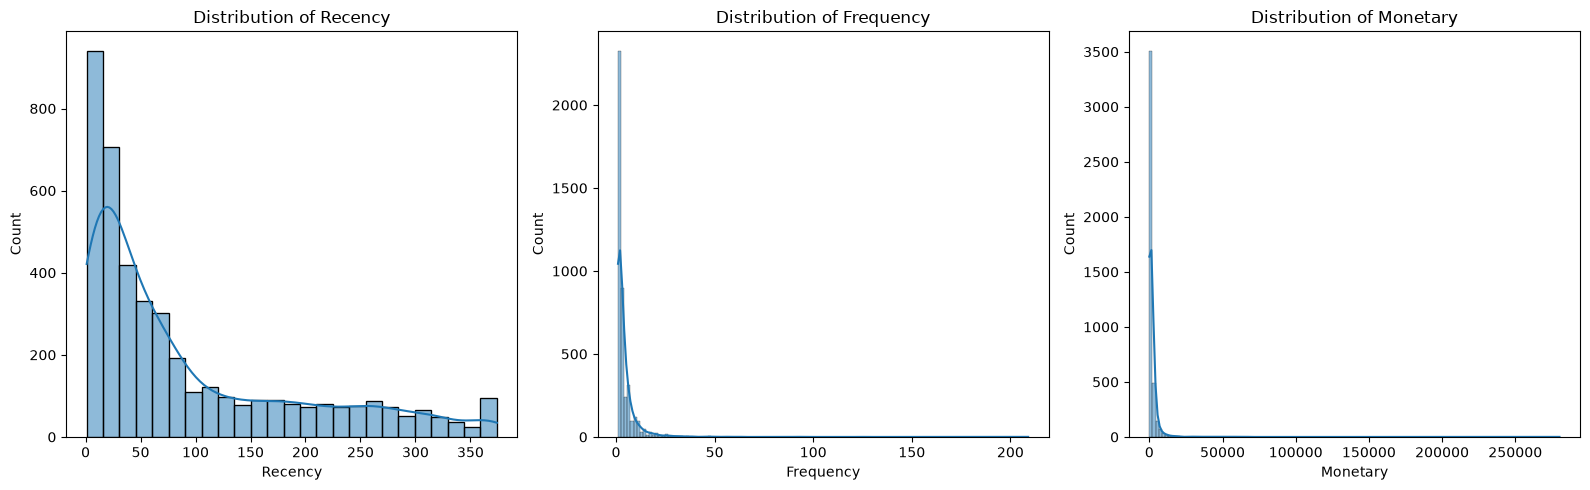

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[col], kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

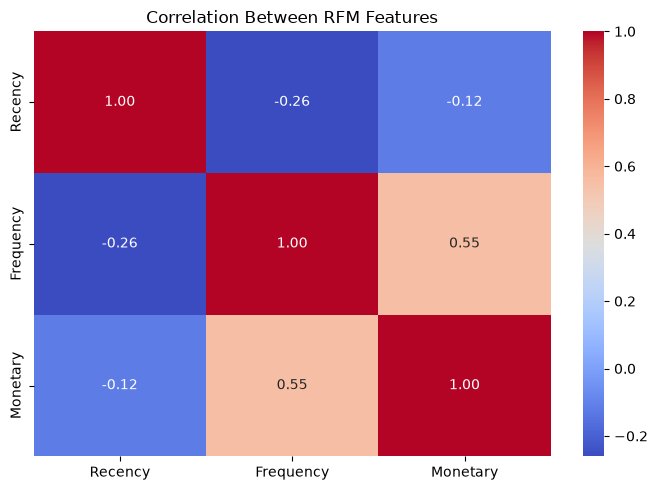

In [5]:
plt.figure(figsize=(7, 5))

correlation = rfm[["Recency", "Frequency", "Monetary"]].corr()

sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f")

plt.title("Correlation Between RFM Features")
plt.tight_layout()
plt.show()

## 3. Logarithmic Transformation

The RFM distributions are examined for skewness and extreme values.

Customer transaction data often exhibits right-skewed distributions, particularly in Frequency and Monetary features.

To reduce the influence of extreme values, the `log1p()` transformation is applied.

\[
X_{transformed} = \log(1+X)
\]

The transformation preserves zero values if present and compresses large numerical values, making the distributions more suitable for distance-based clustering.

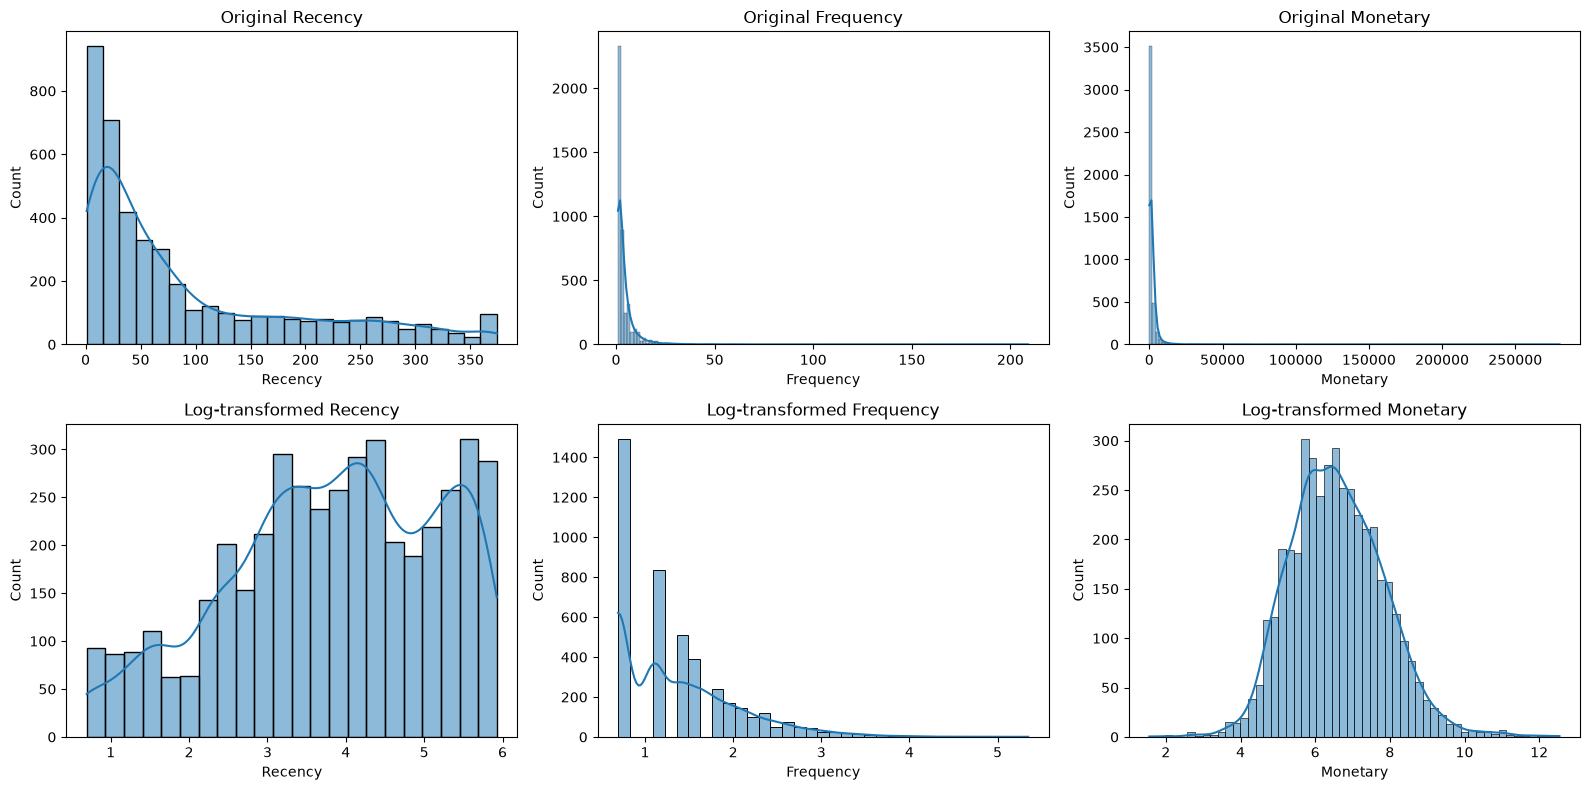

In [6]:
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()


rfm_log = np.log1p(rfm_features)


fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, col in enumerate(rfm_features.columns):
    sns.histplot(rfm_features[col], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"Original {col}")

    sns.histplot(rfm_log[col], kde=True, ax=axes[1, i])
    axes[1, i].set_title(f"Log-transformed {col}")

plt.tight_layout()
plt.show()

## 4. Training and Testing Split

The transformed RFM dataset is divided into training and testing subsets using an 80:20 ratio.

The training set is used to fit the preprocessing scaler and develop the clustering models. The testing set is kept separate for evaluating the clustering results.

This separation helps prevent information from the testing data from influencing the preprocessing and model-selection process.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(rfm_log,test_size=0.20,random_state=RANDOM_SEED)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (3470, 3)
Testing set: (868, 3)


## 5. Feature Standardization

After logarithmic transformation, the RFM features are standardized using `StandardScaler`.

Standardization transforms each feature to have approximately zero mean and unit variance.

\[
Z = \frac{X-\mu}{\sigma}
\]

Here, \(\mu\) represents the training-set mean and \(\sigma\) represents the training-set standard deviation.

The scaler is fitted only on the training data and then applied to both training and testing datasets to prevent data leakage.

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(X_train)


X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (3470, 3)
Testing data shape: (868, 3)


In [9]:
print("Training feature means:")
print(X_train_scaled.mean(axis=0))

print("\nTraining feature standard deviations:")
print(X_train_scaled.std(axis=0))

Training feature means:
[1.10574374e-16 2.38553973e-16 1.00336006e-16]

Training feature standard deviations:
[1. 1. 1.]


## 6. K-Means Clustering

K-Means is used as the baseline clustering algorithm to group customers based on their purchasing behaviour.

The algorithm partitions customers into a predefined number of clusters by minimizing the within-cluster sum of squared distances.

The optimal number of clusters is investigated using the Elbow Method and Silhouette Score.

The models are fitted using the standardized training dataset.

In [10]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:

    kmeans = KMeans(n_clusters=k,random_state=RANDOM_SEED,n_init=10)

    labels = kmeans.fit_predict(X_train_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(silhouette_score(X_train_scaled, labels))

    print(f"K={k}, Inertia={kmeans.inertia_:.2f}, Silhouette={silhouette_values[-1]:.4f}")


K=2, Inertia=5182.82, Silhouette=0.4327
K=3, Inertia=3903.76, Silhouette=0.3344
K=4, Inertia=3158.21, Silhouette=0.3359
K=5, Inertia=2659.72, Silhouette=0.3139
K=6, Inertia=2304.36, Silhouette=0.3076
K=7, Inertia=2056.98, Silhouette=0.3061
K=8, Inertia=1883.88, Silhouette=0.2987
K=9, Inertia=1744.67, Silhouette=0.2792
K=10, Inertia=1622.68, Silhouette=0.2754


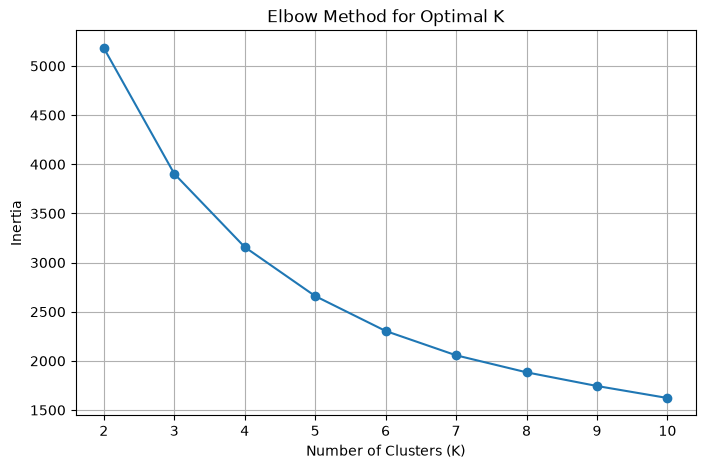

In [11]:

plt.figure(figsize=(8, 5))

plt.plot(list(k_values),inertia_values,marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


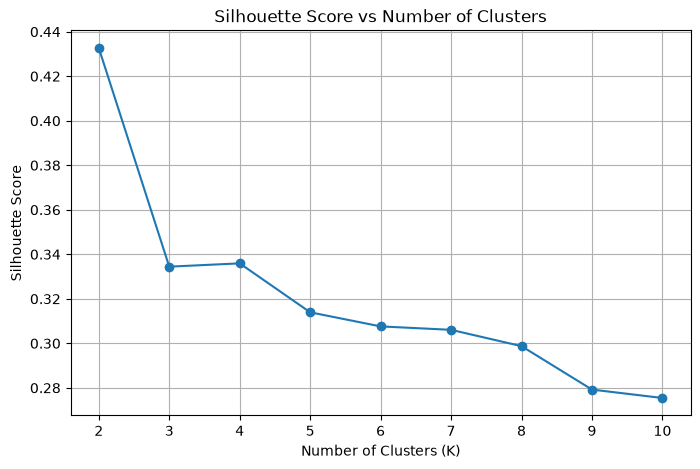

In [12]:

plt.figure(figsize=(8, 5))

plt.plot(list(k_values),silhouette_values,marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs Number of Clusters")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


In [13]:

k_results = pd.DataFrame({"K": list(k_values),"Inertia": inertia_values,"Silhouette Score": silhouette_values})

k_results


,K,Inertia,Silhouette Score
0,2,5182.819222,0.432687
1,3,3903.763951,0.334445
2,4,3158.211105,0.335928
3,5,2659.719031,0.313941
4,6,2304.362166,0.307607
5,7,2056.978911,0.306069
6,8,1883.876720,0.298730
7,9,1744.670636,0.279220
8,10,1622.677872,0.275441


## 7. Gaussian Mixture Model (GMM)

Gaussian Mixture Model (GMM) is implemented as an alternative clustering algorithm to K-Means.

Unlike K-Means, which assigns customers to clusters based on distances from cluster centroids, GMM models the data as a mixture of Gaussian probability distributions.

GMM provides probabilistic cluster assignments and supports different covariance structures.

The optimal number of components and covariance type are selected using the Bayesian Information Criterion (BIC). A lower BIC value indicates a better trade-off between model fit and model complexity.

In [14]:

from sklearn.mixture import GaussianMixture

n_components = range(2, 11)

covariance_types = ["full","tied","diag","spherical"]

gmm_results = []

for covariance in covariance_types:
    for k in n_components:

        gmm = GaussianMixture(
            n_components=k,
            covariance_type=covariance,
            random_state=RANDOM_SEED,
            n_init=3,
            reg_covar=1e-5
        )

        gmm.fit(X_train_scaled)

        gmm_results.append({
            "K": k,
            "Covariance": covariance,
            "BIC": gmm.bic(X_train_scaled),
            "AIC": gmm.aic(X_train_scaled)
        })

gmm_results = pd.DataFrame(gmm_results)

gmm_results.sort_values("BIC").head(10)


,K,Covariance,BIC,AIC
8,10,full,382.996793,-226.042284
25,9,diag,1526.045393,1144.626981
7,9,full,1640.885964,1093.365985
26,10,diag,1686.183620,1261.701839
24,8,diag,3744.122647,3405.767604
6,8,full,3925.134802,3439.133922
4,6,full,4260.352248,3897.389565
5,7,full,4278.423186,3853.941405
22,6,diag,4328.014198,4075.785893
23,7,diag,4358.574738,4063.283064


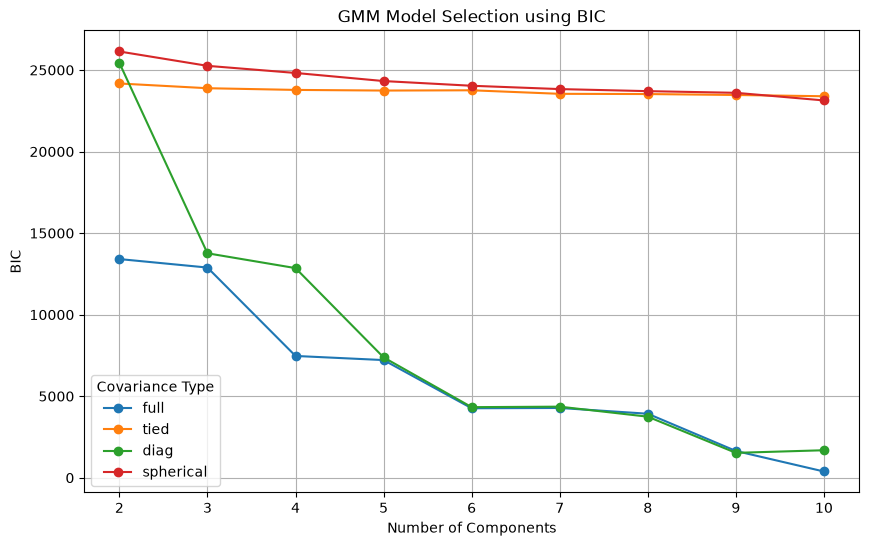

In [15]:

plt.figure(figsize=(10, 6))

for covariance in covariance_types:

    subset = gmm_results[
        gmm_results["Covariance"] == covariance
    ]

    plt.plot(
        subset["K"],
        subset["BIC"],
        marker="o",
        label=covariance
    )

plt.xlabel("Number of Components")
plt.ylabel("BIC")
plt.title("GMM Model Selection using BIC")
plt.legend(title="Covariance Type")
plt.grid(True)
plt.show()


## 8. Training the Selected GMM Model

Based on the BIC comparison, the Gaussian Mixture Model with 10 components and full covariance is selected.

The selected model is fitted on the standardized training dataset. The trained model is then used to predict cluster assignments for the held-out testing dataset.

In [16]:

best_gmm = GaussianMixture(
    n_components=10,
    covariance_type="full",
    random_state=42,
    n_init=3,
    reg_covar=1e-5
)

# Train the model
best_gmm.fit(X_train_scaled)

# Predict cluster assignments
gmm_train_labels = best_gmm.predict(X_train_scaled)
gmm_test_labels = best_gmm.predict(X_test_scaled)

print("Training cluster distribution:")
print(pd.Series(gmm_train_labels).value_counts().sort_index())

print("\nTesting cluster distribution:")
print(pd.Series(gmm_test_labels).value_counts().sort_index())


Training cluster distribution:
0    251
1    394
2    476
3    328
4     44
5    310
6    653
7    202
8    734
9     78
Name: count, dtype: int64

Testing cluster distribution:
0     54
1    112
2    134
3     91
4     17
5     78
6    181
7     40
8    148
9     13
Name: count, dtype: int64


In [17]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score
)

gmm_silhouette = silhouette_score(
    X_test_scaled,
    gmm_test_labels
)

gmm_db = davies_bouldin_score(
    X_test_scaled,
    gmm_test_labels
)

print("GMM Test Silhouette Score:", gmm_silhouette)
print("GMM Test Davies-Bouldin Index:", gmm_db)


GMM Test Silhouette Score: 0.08423117565626007
GMM Test Davies-Bouldin Index: 2.3906421514971865


## 9. Training the Selected K-Means Model

Based on the Elbow Method and Silhouette Score analysis, K=2 is selected as the baseline configuration because it achieved the highest Silhouette Score among the tested cluster counts.

The model is fitted on the standardized training dataset and used to predict cluster assignments for the testing dataset.

In [18]:

best_kmeans = KMeans(
    n_clusters=2,
    random_state=RANDOM_SEED,
    n_init=10
)

best_kmeans.fit(X_train_scaled)

kmeans_train_labels = best_kmeans.predict(X_train_scaled)
kmeans_test_labels = best_kmeans.predict(X_test_scaled)

print("K-Means training clusters:")
print(pd.Series(kmeans_train_labels).value_counts().sort_index())

print("\nK-Means testing clusters:")
print(pd.Series(kmeans_test_labels).value_counts().sort_index())


K-Means training clusters:
0    1334
1    2136
Name: count, dtype: int64

K-Means testing clusters:
0    337
1    531
Name: count, dtype: int64


In [19]:

# Calculate test metrics for K-Means
kmeans_silhouette = silhouette_score(
    X_test_scaled,
    kmeans_test_labels
)

kmeans_db = davies_bouldin_score(
    X_test_scaled,
    kmeans_test_labels
)

# Compare both models
comparison = pd.DataFrame({
    "Model": ["K-Means", "GMM"],
    "Silhouette Score": [
        kmeans_silhouette,
        gmm_silhouette
    ],
    "Davies-Bouldin Index": [
        kmeans_db,
        gmm_db
    ]
})

comparison


,Model,Silhouette Score,Davies-Bouldin Index
0,K-Means,0.433129,0.893725
1,GMM,0.084231,2.390642


## 10. Clustering Stability Analysis

Clustering stability is evaluated to determine whether the algorithms produce consistent customer groupings across different random initializations.

Both K-Means and Gaussian Mixture Models are trained using 10 different random seeds while keeping their selected hyperparameters fixed.

The Adjusted Rand Index (ARI) is used to compare the cluster assignments obtained from different runs.

A higher ARI indicates greater consistency between clustering results, with a value of 1 representing identical partitions.

In [20]:

from itertools import combinations

def calculate_stability(model_type, X, seeds):

    all_labels = []

    for seed in seeds:

        if model_type == "KMeans":
            model = KMeans(
                n_clusters=2,
                random_state=seed,
                n_init=10
            )

        elif model_type == "GMM":
            model = GaussianMixture(
                n_components=10,
                covariance_type="full",
                random_state=seed,
                n_init=3,
                reg_covar=1e-5
            )

        labels = model.fit_predict(X)
        all_labels.append(labels)

    ari_scores = [
        adjusted_rand_score(all_labels[i], all_labels[j])
        for i, j in combinations(range(len(seeds)), 2)
    ]

    return np.mean(ari_scores), np.std(ari_scores)


seeds = range(10)

kmeans_ari_mean, kmeans_ari_std = calculate_stability(
    "KMeans", X_train_scaled, seeds
)

gmm_ari_mean, gmm_ari_std = calculate_stability(
    "GMM", X_train_scaled, seeds
)

stability_results = pd.DataFrame({
    "Model": ["K-Means", "GMM"],
    "Mean ARI": [kmeans_ari_mean, gmm_ari_mean],
    "ARI Std": [kmeans_ari_std, gmm_ari_std]
})

stability_results


,Model,Mean ARI,ARI Std
0,K-Means,1.000000,0.000000
1,GMM,0.894122,0.057109


In [21]:

# Transform all customers using the scaler fitted on training data
X_all_scaled = scaler.transform(rfm_log)

# Assign every customer to a K-Means cluster
rfm_profile = rfm.copy()

rfm_profile["Cluster"] = best_kmeans.predict(X_all_scaled)

# Calculate average RFM values for each cluster

cluster_profile = rfm_profile.groupby("Cluster").agg({
    "CustomerID": "count",
    "Recency": ["mean", "median"],
    "Frequency": ["mean", "median"],
    "Monetary": ["mean", "median"]
})

cluster_profile



CustomerID     Recency        Frequency            Monetary         
             count        mean median      mean median         mean   median
Cluster                                                                     
0             1671   26.052663   16.0  8.431478    6.0  4529.867499  2055.51
1             2667  134.191601   96.0  1.665917    1.0   494.113349   361.62

## 12. PCA-Based Cluster Visualization

Principal Component Analysis (PCA) is used to reduce the three-dimensional standardized RFM feature space into two dimensions for visualization.

The first two principal components capture the largest possible amount of variance in the data.

The resulting two-dimensional representation is used to visualize the customer clusters generated by K-Means.

PCA is used for visualization only; the clustering model continues to use all three RFM features.

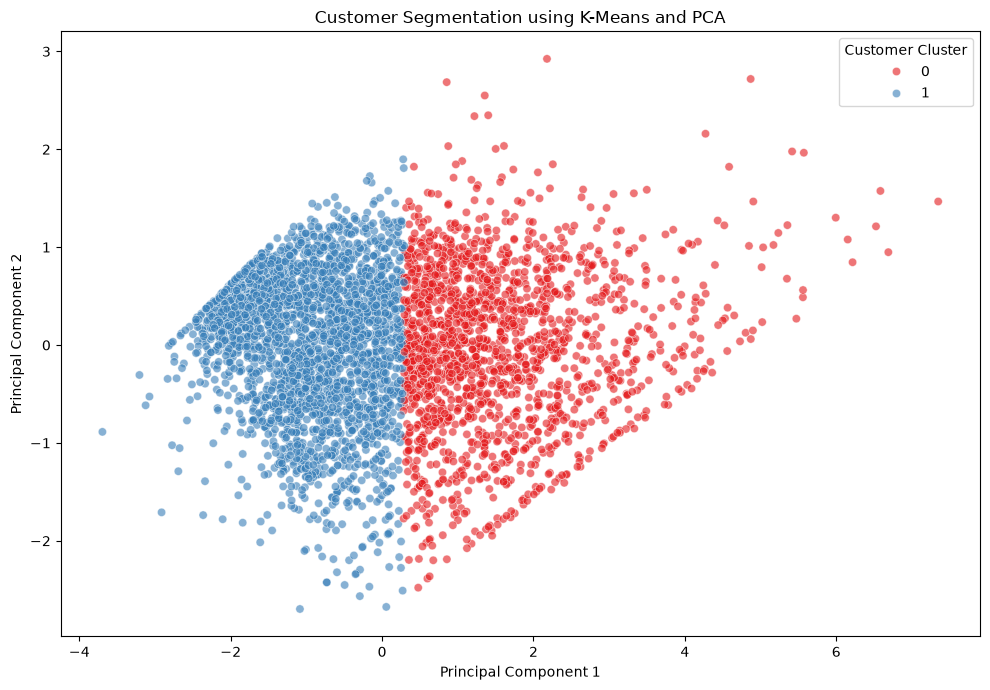

Explained variance ratio: [0.75111868 0.18742061]
Total variance explained: 0.9385392881645374


In [33]:

from sklearn.decomposition import PCA
from pathlib import Path

output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)


# Reduce the three standardized features to two dimensions
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_all_scaled)

# Prepare visualization data
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": rfm_profile["Cluster"].values
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    alpha=0.6
)

plt.title("Customer Segmentation using K-Means and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Cluster")
plt.tight_layout()

plt.savefig(output_dir / "kmeans_pca_clusters.png",dpi=300,bbox_inches="tight")

plt.show()

print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_
)

print(
    "Total variance explained:",
    pca.explained_variance_ratio_.sum()
)


### PCA Visualization Results

The PCA transformation reduced the three-dimensional RFM feature space to two principal components.

The first principal component explains approximately 75.11% of the total variance, while the second component explains approximately 18.74%.

Together, the two components preserve approximately 93.85% of the total variance.

The resulting scatter plot provides a two-dimensional visualization of the customer segments identified by the K-Means algorithm.

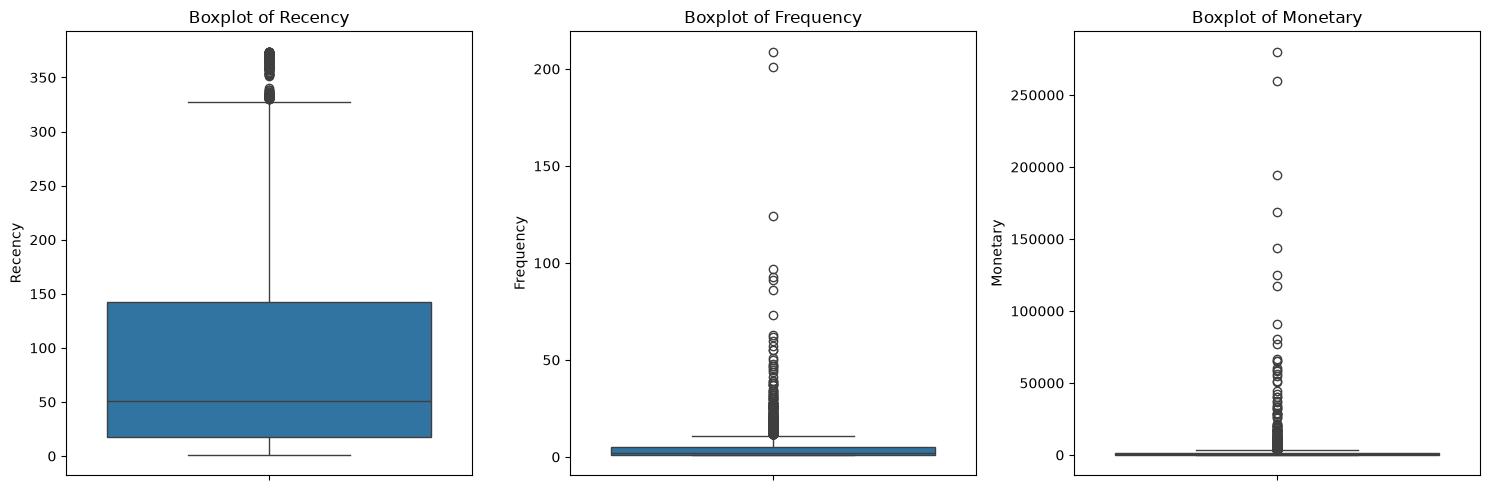

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, col in enumerate(["Recency", "Frequency", "Monetary"]):
    sns.boxplot(y=rfm[col], ax=axes[i])
    axes[i].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()


In [24]:
print("GMM converged:", best_gmm.converged_)
print("Iterations:", best_gmm.n_iter_)

GMM converged: True
Iterations: 28


In [25]:
from pathlib import Path

results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

In [31]:
rfm_profile.to_csv(results_dir / "customer_segments.csv",index=False)

cluster_profile.to_csv(results_dir / "cluster_profiles.csv")
comparison.to_csv(results_dir / "model_comparison.csv",index=False)
k_results.to_csv(results_dir / "kmeans_selection.csv",index=False)
gmm_results.to_csv(results_dir / "gmm_selection.csv",index=False)
stability_results.to_csv(results_dir / "stability_results.csv",index=False)